# Additional models and evaluation

Data extraction, target mappings and the feature scheme follow `data7703.ipynb`.

The Python kernel uses the package versions listed in `RESULTS.md`. Running all cells reuses saved fits by default. `REFIT_MODELS=True` repeats all model fitting; `DATA` sets the source-file location.

In [1]:
from pathlib import Path
import hashlib
import joblib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display

DATA = Path('../clinvar.csv')
CACHE = Path('data/prepared.joblib')
CACHE.parent.mkdir(exist_ok=True)

LABELS = ['Benign', 'Likely_benign', 'Likely_pathogenic', 'Pathogenic']
FREQUENCIES = ['AF_EXAC', 'AF_TGP', 'AF_ESP']
FEATURES = ['CHROM', 'POS', *FREQUENCIES, 'CLNVC', 'MC_Clean', 'Primary_Gene']
target_keys = ['CLNVC', 'CLNVCSO', 'GENEINFO', 'MC', *FREQUENCIES]

import gc
import itertools
import platform
from importlib.metadata import version
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMClassifier, early_stopping
from xgboost import XGBClassifier

%matplotlib inline
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110, 'savefig.dpi': 180,
                     'axes.spines.top': False, 'axes.spines.right': False})
class_names = {'four_class': LABELS, 'binary': ['Benign group', 'Pathogenic group']}


## Data and common partitions

Features include CHROM, POS, AF_EXAC, AF_TGP, AF_ESP, CLNVC, molecular consequence and primary-gene frequency. Gene and molecular-consequence fields use the first listed entry. Missing allele frequencies are filled with zero.

One-hot encoding uses `drop_first=True`. Category vocabularies and gene frequencies are fitted on training rows. Both tasks share test records and use separate validation and probability-calibration partitions.

`Primary_Gene` is assigned to the frame used for training; the raw `MC` column is removed after consequence extraction.

In [2]:
# Group notebook extraction rules
def extract_all_specified_info(info_str):
    if pd.isna(info_str):
        return {key: None for key in target_keys}
    info_dict = {}
    for pair in info_str.split(';'):
        if '=' in pair:
            key, value = pair.split('=', 1)
            info_dict[key] = value
    result = {}
    for key in target_keys:
        value = info_dict.get(key)
        if key in FREQUENCIES:
            try:
                result[key] = float(value) if value is not None else 0.0
            except ValueError:
                result[key] = 0.0
        else:
            result[key] = value
    return result

def clean_geneinfo(gene_str):
    if pd.isna(gene_str):
        return 'Unknown'
    return gene_str.split('|')[0].split(':')[0]

def clean_mc(mc_str):
    if pd.isna(mc_str) or mc_str == 'None':
        return 'Unknown'
    first_part = str(mc_str).split(',')[0]
    return first_part.split('|', 1)[1] if '|' in first_part else first_part

def encode_features(training, frame):
    levels = {column: sorted(training[column].dropna().astype(str).unique())
              for column in ['CHROM', 'CLNVC', 'MC_Clean']}
    values = frame[FEATURES].copy()
    for column, categories in levels.items():
        labels = values[column].astype(str)
        values[column] = pd.Categorical(labels.where(labels.isin(categories)), categories=categories)
    values = pd.get_dummies(values, columns=list(levels), drop_first=True, dtype=np.float32)
    gene_counts = training['Primary_Gene'].value_counts()
    values['Primary_Gene_Freq'] = values['Primary_Gene'].astype(str).map(gene_counts).fillna(0).astype(np.float32)
    values = values.drop(columns='Primary_Gene')
    return values.to_numpy(dtype=np.float32), values.columns.tolist()


In [3]:
if CACHE.exists():
    prepared = joblib.load(CACHE)
    assert prepared['source_bytes'] == DATA.stat().st_size
    with DATA.open('rb') as stream:
        assert prepared['source_sha256'] == hashlib.file_digest(stream, 'sha256').hexdigest()
else:
    frames = []
    for chunk in pd.read_csv(DATA, dtype={'CHROM': str},
                             usecols=['CHROM', 'POS', 'REF', 'ALT', 'CLNSIG', 'INFO'],
                             chunksize=100_000):
        extracted = pd.DataFrame(chunk['INFO'].apply(extract_all_specified_info).tolist())
        data_ready = pd.concat([chunk.drop(columns='INFO').reset_index(drop=True), extracted], axis=1)
        data_ready['Primary_Gene'] = data_ready['GENEINFO'].apply(clean_geneinfo)
        data_ready['MC_Clean'] = data_ready['MC'].apply(clean_mc)
        data_ready = data_ready.drop(columns=['GENEINFO', 'MC', 'CLNVCSO'])
        data_ready[FREQUENCIES] = data_ready[FREQUENCIES].fillna(0.0)
        data_ready['CLNVC'] = data_ready['CLNVC'].fillna('Unknown')
        frames.append(data_ready)
    data_ready = pd.concat(frames, ignore_index=True)
    clnsig_4way_mapping = {
        'Benign': 'Benign', 'Benign/Likely_benign': 'Likely_benign',
        'Likely_benign': 'Likely_benign', 'Pathogenic': 'Pathogenic',
        'Pathogenic/Likely_pathogenic': 'Likely_pathogenic',
        'Likely_pathogenic': 'Likely_pathogenic'}
    clinical = data_ready['CLNSIG'].map(clnsig_4way_mapping)
    assert clinical.notna().all()
    y4 = clinical.map(dict(zip(LABELS, range(4)))).to_numpy(dtype=np.int8)
    y2 = (y4 >= 2).astype(np.int8)
    keys = ['CHROM', 'POS', 'REF', 'ALT']
    assert not data_ready.duplicated(keys).any()
    assert data_ready[keys].notna().all().all()
    indices = np.arange(len(data_ready))
    development, test = train_test_split(indices, test_size=.30, stratify=y4, random_state=42)
    train, remaining = train_test_split(development, test_size=.20,
                                        stratify=y4[development], random_state=42)
    calibration, validation = train_test_split(remaining, test_size=.50,
                                               stratify=y4[remaining], random_state=42)
    splits = dict(train=train, calibration=calibration, validation=validation, test=test)
    assert np.unique(np.concatenate(list(splits.values()))).size == len(data_ready)
    X, feature_names = encode_features(data_ready.iloc[train], data_ready)
    assert np.isfinite(X).all()
    for column in ['CHROM', 'CLNVC', 'MC_Clean', 'Primary_Gene', 'CLNSIG', 'REF', 'ALT']:
        data_ready[column] = data_ready[column].astype('category')
    with DATA.open('rb') as stream:
        source_sha256 = hashlib.file_digest(stream, 'sha256').hexdigest()
    prepared = dict(data=data_ready, X=X, y={'four_class': y4, 'binary': y2},
                    splits=splits, feature_names=feature_names, source_sha256=source_sha256,
                    source_bytes=DATA.stat().st_size, source_commit='b6e0bef')
    joblib.dump(prepared, CACHE, compress=3)

data_ready = prepared['data']
X = prepared['X']
splits = prepared['splits']
print(f"Variants: {len(data_ready):,}; encoded features: {X.shape[1]}")
display(pd.Series({name: len(rows) for name, rows in splits.items()}, name='Rows').to_frame())
display(data_ready['CLNSIG'].value_counts().rename('Rows').to_frame())


Variants: 1,686,794; encoded features: 56


,Rows
train,944604
calibration,118075
validation,118076
test,506039


,Rows
CLNSIG,
Likely_benign,1081389
Benign,209662
Pathogenic,185024
Likely_pathogenic,110549
Benign/Likely_benign,63543
Pathogenic/Likely_pathogenic,36627


In [4]:
targets = prepared['y']
feature_names = prepared['feature_names']
STATE = Path('data/experiment.joblib')
REFIT_MODELS = False
state = {}
if STATE.exists() and not REFIT_MODELS:
    state = joblib.load(STATE)
    assert state['source_sha256'] == prepared['source_sha256']
    assert state['design'] == 'group-jupyter-v1'
    models = state['models']
else:
    models = {}
gene_experiment = state.get('gene_experiment')

def checkpoint():
    temporary = STATE.with_suffix('.tmp')
    joblib.dump(dict(models=models, source_sha256=prepared['source_sha256'],
                     design='group-jupyter-v1', gene_experiment=gene_experiment), temporary, compress=3)
    temporary.replace(STATE)

def scores(actual, probability, task):
    predicted = probability.argmax(axis=1)
    positive = actual >= 2 if task == 'four_class' else actual == 1
    predicted_positive = predicted >= 2 if task == 'four_class' else predicted == 1
    return dict(accuracy=float(accuracy_score(actual, predicted)),
                macro_f1=float(f1_score(actual, predicted, average='macro', zero_division=0)),
                weighted_f1=float(f1_score(actual, predicted, average='weighted', zero_division=0)),
                balanced_accuracy=float(balanced_accuracy_score(actual, predicted)),
                disease_recall=float(recall_score(positive, predicted_positive, zero_division=0)),
                disease_precision=float(precision_score(positive, predicted_positive, zero_division=0)),
                false_negatives=int(np.count_nonzero(positive & ~predicted_positive)))

def features(rows, as_frame=False):
    values = X[rows]
    return pd.DataFrame(values, columns=feature_names) if as_frame else values

def predict_checked(model, values, task):
    assert np.array_equal(model.classes_, np.arange(len(class_names[task])))
    probability = model.predict_proba(values).astype(np.float32)
    assert np.isfinite(probability).all() and (probability >= 0).all()
    assert np.allclose(probability.sum(axis=1), 1, atol=1e-5)
    return probability

def calibrate(base, task, as_frame=False):
    model = CalibratedClassifierCV(FrozenEstimator(base), method='sigmoid')
    model.fit(features(splits['calibration'], as_frame), targets[task][splits['calibration']])
    probability = predict_checked(model, features(splits['validation'], as_frame), task)
    metric = scores(targets[task][splits['validation']], probability, task)
    return dict(model=model, base_model=base, validation=probability,
                validation_metrics=metric, as_frame=as_frame)

def select_candidate(candidates):
    return max(candidates, key=lambda item: (item['validation_metrics']['macro_f1'],
                                            item['validation_metrics']['disease_recall']))

def test_selected(name, task, selected, candidates):
    selected['test'] = predict_checked(selected['model'], features(splits['test'], selected['as_frame']), task)
    selected['test_metrics'] = scores(targets[task][splits['test']], selected['test'], task)
    selected['candidates'] = [dict(variant=c['variant'], **c['validation_metrics']) for c in candidates]
    models.setdefault(name, {})[task] = selected
    print(name, task, selected['variant'])
    display(pd.DataFrame(selected['candidates']).set_index('variant').round(5))
    display(pd.Series(selected['test_metrics'], name='Test').to_frame().round(5))
    print(classification_report(targets[task][splits['test']], selected['test'].argmax(axis=1),
          target_names=class_names[task], digits=4, zero_division=0))

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def show_cached(name):
    for task, result in models[name].items():
        print(name, task, result['variant'], '(saved fit)')
        display(pd.DataFrame(result['candidates']).round(5))
        display(pd.Series(result['test_metrics'], name='Test').to_frame().round(5))
        print(classification_report(targets[task][splits['test']], result['test'].argmax(axis=1),
                                    target_names=class_names[task], digits=4, zero_division=0))


## AdaBoost

The candidates use 60 depth-2 trees, learning rate 0.5 and seed 42. Standard and balanced sample weights are compared. Each fitted candidate is sigmoid-calibrated on the calibration partition. Validation macro-F1 selects the candidate before test evaluation.

In [5]:
if 'AdaBoost' not in models:
    for task in ['four_class', 'binary']:
        candidates = []
        for variant in ['standard', 'balanced']:
            base = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=42),
                                      n_estimators=60, learning_rate=.5, random_state=42)
            weight = (compute_sample_weight('balanced', targets[task][splits['train']])
                      if variant == 'balanced' else None)
            base.fit(features(splits['train']), targets[task][splits['train']], sample_weight=weight)
            candidate = calibrate(base, task)
            candidate['variant'] = variant
            candidates.append(candidate)
        test_selected('AdaBoost', task, select_candidate(candidates), candidates)
        del candidates, candidate, base
        gc.collect()
    checkpoint()
else:
    show_cached('AdaBoost')

AdaBoost four_class standard (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,standard,0.83401,0.65357,0.80909,0.61133,0.75092,0.98862,5792
1,balanced,0.83373,0.65089,0.80863,0.60916,0.75170,0.98886,5774


,Test
accuracy,0.83451
macro_f1,0.65597
weighted_f1,0.81003
balanced_accuracy,0.61266
disease_recall,0.75181
disease_precision,0.98838
false_negatives,24735.00000


                   precision    recall  f1-score   support

           Benign     0.9379    0.4473    0.6057     62899
    Likely_benign     0.8518    0.9926    0.9169    343480
Likely_pathogenic     0.7087    0.2539    0.3738     44153
       Pathogenic     0.7003    0.7569    0.7275     55507

         accuracy                         0.8345    506039
        macro avg     0.7997    0.6127    0.6560    506039
     weighted avg     0.8334    0.8345    0.8100    506039

AdaBoost binary balanced (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,standard,0.96330,0.94211,0.96334,0.94299,0.90948,0.90469,2105
1,balanced,0.96408,0.94374,0.96424,0.94779,0.92092,0.89915,1839


,Test
accuracy,0.96377
macro_f1,0.94326
weighted_f1,0.96394
balanced_accuracy,0.94736
disease_recall,0.92028
disease_precision,0.89827
false_negatives,7945.00000


                  precision    recall  f1-score   support

    Benign group     0.9803    0.9744    0.9774    406379
Pathogenic group     0.8983    0.9203    0.9091     99660

        accuracy                         0.9638    506039
       macro avg     0.9393    0.9474    0.9433    506039
    weighted avg     0.9642    0.9638    0.9639    506039



## LinearSVC

The candidates use C=0.1 and C=1, balanced class weights, `dual=False`, 5,000 maximum iterations and seed 42. Training uses sparse input and training-fitted scaling without centering. Sigmoid calibration uses separate calibration rows; C is selected by validation macro-F1.

In [6]:
if 'LinearSVC' not in models:
    sparse_train = csr_matrix(features(splits['train']))
    for task in ['four_class', 'binary']:
        candidates = []
        for c_value in [.1, 1.]:
            base = make_pipeline(StandardScaler(with_mean=False), LinearSVC(C=c_value, class_weight='balanced',
                                 dual=False, max_iter=5000, random_state=42))
            base.fit(sparse_train, targets[task][splits['train']])
            candidate = calibrate(base, task)
            candidate['variant'] = f'C={c_value:g}, balanced'
            candidates.append(candidate)
        test_selected('LinearSVC', task, select_candidate(candidates), candidates)
        del candidates, candidate, base
        gc.collect()
    del sparse_train
    checkpoint()
else:
    show_cached('LinearSVC')

LinearSVC four_class C=1, balanced (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"C=0.1, balanced",0.82752,0.64811,0.80449,0.61135,0.76860,0.97972,5381
1,"C=1, balanced",0.82759,0.64820,0.80454,0.61138,0.76856,0.98031,5382


,Test
accuracy,0.82827
macro_f1,0.65074
weighted_f1,0.80563
balanced_accuracy,0.61301
disease_recall,0.77009
disease_precision,0.97905
false_negatives,22913.00000


                   precision    recall  f1-score   support

           Benign     0.8329    0.4395    0.5754     62899
    Likely_benign     0.8554    0.9823    0.9144    343480
Likely_pathogenic     0.6648    0.2728    0.3868     44153
       Pathogenic     0.6976    0.7575    0.7263     55507

         accuracy                         0.8283    506039
        macro avg     0.7627    0.6130    0.6507    506039
     weighted avg     0.8186    0.8283    0.8056    506039



LinearSVC binary C=1, balanced (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"C=0.1, balanced",0.95071,0.91834,0.94950,0.89959,0.81526,0.92559,4296
1,"C=1, balanced",0.95132,0.91963,0.95022,0.90213,0.82098,0.92334,4163


,Test
accuracy,0.95141
macro_f1,0.91986
weighted_f1,0.95034
balanced_accuracy,0.90272
disease_recall,0.82239
disease_precision,0.92250
false_negatives,17701.00000


                  precision    recall  f1-score   support

    Benign group     0.9576    0.9831    0.9701    406379
Pathogenic group     0.9225    0.8224    0.8696     99660

        accuracy                         0.9514    506039
       macro avg     0.9400    0.9027    0.9199    506039
    weighted avg     0.9507    0.9514    0.9503    506039



## LightGBM

The candidates use up to 350 trees, 31 leaves, learning rate 0.08 and seed 42. Validation early stopping uses 25 rounds. Standard and balanced sample weights are compared after separate sigmoid calibration.

In [7]:
LGB_PARAMETERS = dict(n_estimators=350, num_leaves=31, learning_rate=.08,
                      n_jobs=2, random_state=42, verbosity=-1,
                      deterministic=True, force_col_wise=True)
if 'LightGBM' not in models:
    for task in ['four_class', 'binary']:
        candidates = []
        for variant in ['standard', 'balanced']:
            base = LGBMClassifier(**LGB_PARAMETERS)
            weight = (compute_sample_weight('balanced', targets[task][splits['train']])
                      if variant == 'balanced' else None)
            base.fit(features(splits['train'], True), targets[task][splits['train']], sample_weight=weight,
                     eval_X=features(splits['validation'], True), eval_y=targets[task][splits['validation']],
                     callbacks=[early_stopping(25, verbose=False)])
            candidate = calibrate(base, task, True)
            candidate['variant'] = variant
            candidates.append(candidate)
        test_selected('LightGBM', task, select_candidate(candidates), candidates)
        del candidates, candidate, base
        gc.collect()
    checkpoint()
else:
    show_cached('LightGBM')

LightGBM four_class standard (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,standard,0.86637,0.73913,0.85993,0.71713,0.91928,0.94979,1877
1,balanced,0.86209,0.73630,0.85763,0.71916,0.94784,0.91176,1213


,Test
accuracy,0.86627
macro_f1,0.73979
weighted_f1,0.85999
balanced_accuracy,0.71771
disease_recall,0.91739
disease_precision,0.94801
false_negatives,8233.00000


                   precision    recall  f1-score   support

           Benign     0.8730    0.6342    0.7347     62899
    Likely_benign     0.9169    0.9714    0.9434    343480
Likely_pathogenic     0.6290    0.4766    0.5423     44153
       Pathogenic     0.6949    0.7886    0.7388     55507

         accuracy                         0.8663    506039
        macro avg     0.7785    0.7177    0.7398    506039
     weighted avg     0.8620    0.8663    0.8600    506039



LightGBM binary balanced (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,standard,0.97336,0.95804,0.97341,0.95956,0.93679,0.92860,1470
1,balanced,0.97424,0.95949,0.97430,0.96187,0.94147,0.92869,1361


,Test
accuracy,0.97376
macro_f1,0.95875
weighted_f1,0.97383
balanced_accuracy,0.96132
disease_recall,0.94079
disease_precision,0.92706
false_negatives,5901.00000


                  precision    recall  f1-score   support

    Benign group     0.9854    0.9818    0.9836    406379
Pathogenic group     0.9271    0.9408    0.9339     99660

        accuracy                         0.9738    506039
       macro avg     0.9562    0.9613    0.9588    506039
    weighted avg     0.9739    0.9738    0.9738    506039



## Group-model comparisons

Random Forest retains the group notebook's 150-tree four-class and 100-tree binary settings with balanced-subsample weights. XGBoost retains its 100-tree balanced-weight setting and is also fitted for binary comparison. Both are retrained on the same fitting rows as the additional models and calibrated on the same calibration rows.

In [8]:
if 'RandomForest' not in models or 'XGBoost' not in models:
    for task in ['four_class', 'binary']:
        baselines = [
            ('RandomForest', RandomForestClassifier(n_estimators=150 if task == 'four_class' else 100,
                  class_weight='balanced_subsample', random_state=42, n_jobs=2)),
            ('XGBoost', XGBClassifier(n_estimators=100, random_state=42, n_jobs=2))]
        for name, base in baselines:
            weight = compute_sample_weight('balanced', targets[task][splits['train']]) if name == 'XGBoost' else None
            if weight is None:
                base.fit(features(splits['train']), targets[task][splits['train']])
            else:
                base.fit(features(splits['train']), targets[task][splits['train']], sample_weight=weight)
            selected = calibrate(base, task)
            selected['variant'] = 'group settings, sigmoid'
            test_selected(name, task, selected, [selected])
            models[name][task].pop('model')
            models[name][task].pop('base_model')
            del base, selected
            gc.collect()
        del baselines
    checkpoint()
else:
    show_cached('RandomForest')
    show_cached('XGBoost')

RandomForest four_class group settings, sigmoid (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"group settings, sigmoid",0.85581,0.72437,0.85369,0.71444,0.9407,0.95947,1379


,Test
accuracy,0.85540
macro_f1,0.72401
weighted_f1,0.85328
balanced_accuracy,0.71384
disease_recall,0.93889
disease_precision,0.95718
false_negatives,6090.00000


                   precision    recall  f1-score   support

           Benign     0.7858    0.6982    0.7394     62899
    Likely_benign     0.9319    0.9561    0.9438    343480
Likely_pathogenic     0.5577    0.5382    0.5478     44153
       Pathogenic     0.6672    0.6629    0.6650     55507

         accuracy                         0.8554    506039
        macro avg     0.7356    0.7138    0.7240    506039
     weighted avg     0.8520    0.8554    0.8533    506039

RandomForest binary group settings, sigmoid (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"group settings, sigmoid",0.98039,0.96884,0.98034,0.96627,0.94298,0.95684,1326


...

                   precision    recall  f1-score   support

           Benign     0.7332    0.7752    0.7536     62899
    Likely_benign     0.9492    0.9206    0.9347    343480
Likely_pathogenic     0.5340    0.5594    0.5464     44153
       Pathogenic     0.7052    0.7640    0.7334     55507

         accuracy                         0.8538    506039
        macro avg     0.7304    0.7548    0.7420    506039
     weighted avg     0.8593    0.8538    0.8562    506039



XGBoost binary group settings, sigmoid (saved fit)


,variant,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"group settings, sigmoid",0.97083,0.95485,0.97113,0.96462,0.95437,0.90304,1061


,Test
accuracy,0.97088
macro_f1,0.95496
weighted_f1,0.97119
balanced_accuracy,0.96507
disease_recall,0.95549
disease_precision,0.90238
false_negatives,4436.00000


                  precision    recall  f1-score   support

    Benign group     0.9889    0.9747    0.9817    406379
Pathogenic group     0.9024    0.9555    0.9282     99660

        accuracy                         0.9709    506039
       macro avg     0.9457    0.9651    0.9550    506039
    weighted avg     0.9719    0.9709    0.9712    506039


## Soft voting and F1 comparison

Two pools are compared: the three additional models, and the validation-best three models from the additional and group models. Each pool has equal and validation-selected quarter-step weights; at least two weights are positive. Weights maximize validation macro-F1, with pathogenic-group recall breaking ties. Test metrics follow selection. Macro-F1, weighted F1, balanced accuracy, pathogenic-group precision/recall and false negatives are reported.

four_class SoftVoting_new {'members': ['AdaBoost', 'LinearSVC', 'LightGBM'], 'weights': [0.0, 0.25, 0.75]}


,weights,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"[0.0, 0.25, 0.75]",0.86356,0.73072,0.85496,0.70233,0.89683,0.96328,2399
3,"[0.25, 0.0, 0.75]",0.86357,0.72943,0.85412,0.69890,0.89709,0.96342,2393
7,"[0.5, 0.0, 0.5]",0.85746,0.71187,0.84392,0.67367,0.84097,0.98222,3698
4,"[0.25, 0.25, 0.5]",0.85526,0.70734,0.84121,0.66836,0.84489,0.97966,3607
1,"[0.0, 0.5, 0.5]",0.85096,0.70227,0.83743,0.66656,0.84080,0.97706,3702
10,"[0.75, 0.0, 0.25]",0.84462,0.67571,0.82361,0.63516,0.75239,0.98881,5758
8,"[0.5, 0.25, 0.25]",0.84076,0.66898,0.81895,0.62658,0.76456,0.98761,5475
2,"[0.0, 0.75, 0.25]",0.83320,0.66109,0.81239,0.62339,0.78365,0.97831,5031
5,"[0.25, 0.5, 0.25]",0.83475,0.65745,0.81154,0.61641,0.77157,0.98318,5312
11,"[0.75, 0.25, 0.0]",0.83230,0.65005,0.80677,0.60683,0.75234,0.98859,5759


four_class SoftVoting {'members': ['XGBoost', 'LightGBM', 'RandomForest'], 'weights': [0.5, 0.25, 0.25]}


,weights,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
8,"[0.5, 0.25, 0.25]",0.86902,0.75298,0.86705,0.74546,0.94470,0.94061,1286
5,"[0.25, 0.5, 0.25]",0.87190,0.75282,0.86791,0.73693,0.93528,0.95857,1505
7,"[0.5, 0.0, 0.5]",0.86903,0.74956,0.86648,0.73790,0.93915,0.96471,1415
10,"[0.75, 0.0, 0.25]",0.86307,0.74925,0.86323,0.75144,0.95098,0.91797,1140
2,"[0.0, 0.75, 0.25]",0.87172,0.74870,0.86602,0.72677,0.92810,0.96711,1672
9,"[0.5, 0.5, 0.0]",0.86194,0.74465,0.86092,0.74199,0.94315,0.91544,1322
6,"[0.25, 0.75, 0.0]",0.86600,0.74418,0.86229,0.73109,0.93076,0.93527,1610
4,"[0.25, 0.25, 0.5]",0.86789,0.74412,0.86467,0.72931,0.93808,0.96856,1440
11,"[0.75, 0.25, 0.0]",0.85699,0.74243,0.85792,0.74856,0.94947,0.90266,1175
1,"[0.0, 0.5, 0.5]",0.86576,0.73773,0.86194,0.71997,0.93541,0.97072,1502


binary SoftVoting_new {'members': ['AdaBoost', 'LinearSVC', 'LightGBM'], 'weights': [0.0, 0.25, 0.75]}


,weights,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,"[0.0, 0.25, 0.75]",0.97415,0.95926,0.97419,0.96057,0.93816,0.93111,1438
3,"[0.25, 0.0, 0.75]",0.97392,0.95894,0.97397,0.96091,0.93945,0.92891,1408
1,"[0.0, 0.5, 0.5]",0.97355,0.95795,0.97348,0.95536,0.92535,0.93945,1736
4,"[0.25, 0.25, 0.5]",0.97326,0.95770,0.97325,0.95732,0.93102,0.93307,1604
7,"[0.5, 0.0, 0.5]",0.97294,0.95736,0.97298,0.95874,0.93532,0.92786,1504
8,"[0.5, 0.25, 0.25]",0.97177,0.95520,0.97171,0.95333,0.92289,0.93305,1793
5,"[0.25, 0.5, 0.25]",0.97199,0.95514,0.97181,0.94921,0.91163,0.94423,2055
10,"[0.75, 0.0, 0.25]",0.96979,0.95233,0.96982,0.95316,0.92573,0.92126,1727
2,"[0.0, 0.75, 0.25]",0.96821,0.94835,0.96776,0.93637,0.88385,0.95126,2701
11,"[0.75, 0.25, 0.0]",0.96496,0.94497,0.96507,0.94781,0.91950,0.90422,1872


binary SoftVoting {'members': ['RandomForest', 'LightGBM', 'XGBoost'], 'weights': [0.5, 0.5, 0.0]}


,weights,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
9,"[0.5, 0.5, 0.0]",0.98195,0.97119,0.98186,0.96656,0.94117,0.96631,1368
8,"[0.5, 0.25, 0.25]",0.98191,0.97114,0.98183,0.96689,0.94212,0.96520,1346
7,"[0.5, 0.0, 0.5]",0.98184,0.97108,0.98177,0.96753,0.94392,0.96314,1304
11,"[0.75, 0.25, 0.0]",0.98118,0.97002,0.98111,0.96646,0.94216,0.96151,1345
10,"[0.75, 0.0, 0.25]",0.98115,0.96997,0.98108,0.96645,0.94220,0.96130,1344
6,"[0.25, 0.75, 0.0]",0.97952,0.96746,0.97947,0.96508,0.94126,0.95414,1366
5,"[0.25, 0.5, 0.25]",0.97856,0.96614,0.97857,0.96672,0.94719,0.94411,1228
4,"[0.25, 0.25, 0.5]",0.97545,0.96159,0.97557,0.96638,0.95141,0.92596,1130
3,"[0.25, 0.0, 0.75]",0.97343,0.95866,0.97364,0.96595,0.95360,0.91507,1079
2,"[0.0, 0.75, 0.25]",0.97295,0.95774,0.97311,0.96313,0.94693,0.91827,1234


,task,model,variant,validation_macro_f1,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,four_class,AdaBoost,standard,0.65357,0.83451,0.65597,0.81003,0.61266,0.75181,0.98838,24735
1,binary,AdaBoost,balanced,0.94374,0.96377,0.94326,0.96394,0.94736,0.92028,0.89827,7945
2,four_class,LinearSVC,"C=1, balanced",0.64820,0.82827,0.65074,0.80563,0.61301,0.77009,0.97905,22913
3,binary,LinearSVC,"C=1, balanced",0.91963,0.95141,0.91986,0.95034,0.90272,0.82239,0.92250,17701
4,four_class,LightGBM,standard,0.73913,0.86627,0.73979,0.85999,0.71771,0.91739,0.94801,8233
5,binary,LightGBM,balanced,0.95949,0.97376,0.95875,0.97383,0.96132,0.94079,0.92706,5901
6,four_class,RandomForest,"group settings, sigmoid",0.72437,0.85540,0.72401,0.85328,0.71384,0.93889,0.95718,6090
7,binary,RandomForest,"group settings, sigmoid",0.96884,0.97961,0.96760,0.97956,0.96521,0.94145,0.95439,5835
8,four_class,XGBoost,"group settings, sigmoid",0.74077,0.85383,0.74202,0.85620,0.75481,0.95389,0.89354,4595
9,binary,XGBoost,"group settings, sigmoid",0.95485,0.97088,0.95496,0.97119,0.96507,0.95549,0.90238,4436


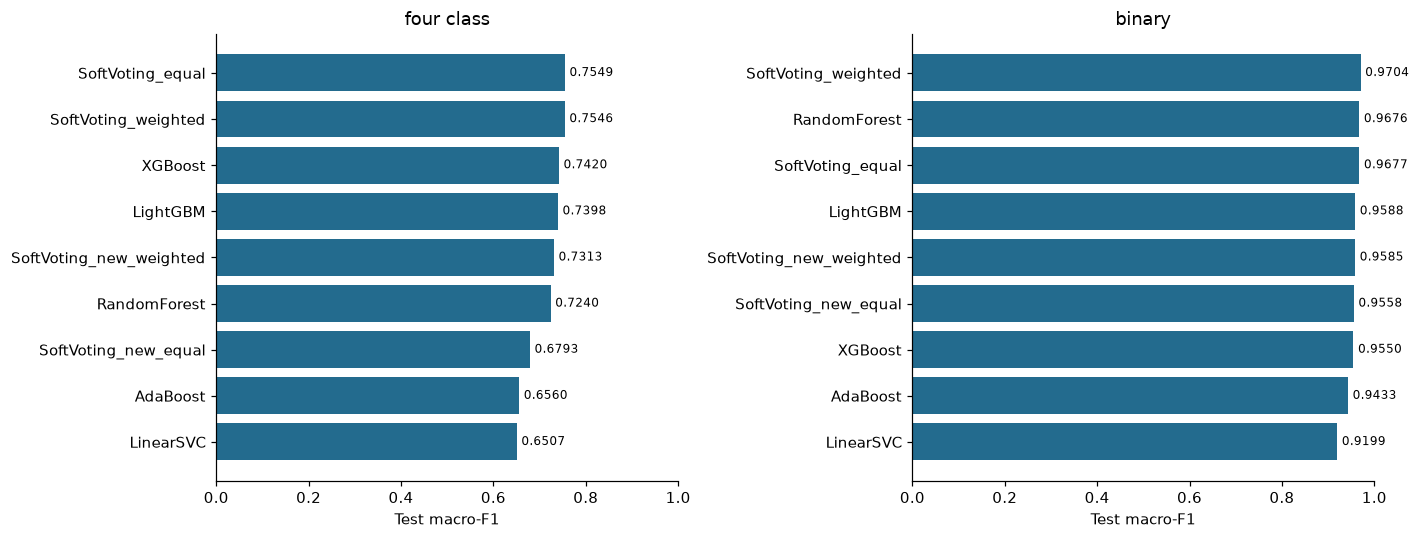

In [9]:
new_members = ['AdaBoost', 'LinearSVC', 'LightGBM']
base_members = new_members + ['RandomForest', 'XGBoost']
selections = {}
for task in ['four_class', 'binary']:
    y_validation = targets[task][splits['validation']]
    best_three = sorted(base_members, key=lambda name: models[name][task]['validation_metrics']['macro_f1'], reverse=True)[:3]
    selections[task] = {}
    for prefix, members in [('SoftVoting_new', new_members), ('SoftVoting', best_three)]:
        candidate_weights = []
        for a in range(5):
            for b in range(5-a):
                weights = np.array([a, b, 4-a-b], dtype=float) / 4
                if np.count_nonzero(weights) < 2:
                    continue
                probability = sum(w * models[name][task]['validation'] for w, name in zip(weights, members))
                candidate_weights.append(dict(weights=weights, **scores(y_validation, probability, task)))
        chosen = max(candidate_weights, key=lambda row: (row['macro_f1'], row['disease_recall']))
        selections[task][prefix] = dict(members=members, weights=chosen['weights'].tolist())
        for suffix, weights in [('equal', np.ones(3)/3), ('weighted', chosen['weights'])]:
            validation = sum(w * models[member][task]['validation'] for w, member in zip(weights, members))
            test = sum(w * models[member][task]['test'] for w, member in zip(weights, members))
            models.setdefault(prefix + '_' + suffix, {})[task] = dict(variant=str({member: float(w) for member, w in zip(members, weights)}),
                validation=validation, test=test, validation_metrics=scores(y_validation, validation, task),
                test_metrics=scores(targets[task][splits['test']], test, task))
        print(task, prefix, selections[task][prefix])
        display(pd.DataFrame([{**row, 'weights': row['weights'].tolist()} for row in candidate_weights])
                .sort_values('macro_f1', ascending=False).round(5))

comparison = pd.DataFrame([dict(task=task, model=name, variant=result['variant'],
                 validation_macro_f1=result['validation_metrics']['macro_f1'], **result['test_metrics'])
                 for name, tasks in models.items() for task, result in tasks.items()])
display(comparison.round(5))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, task in zip(axes, ['four_class', 'binary']):
    table = comparison.loc[comparison['task'] == task].sort_values('validation_macro_f1')
    bars = ax.barh(table['model'], table['macro_f1'], color='#236b8e')
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    ax.set(xlabel='Test macro-F1', title=task.replace('_', ' '), xlim=(0, 1))
save_figure(fig, 'model_comparison.png')


## Binary thresholds

Thresholds are selected on validation probabilities of the weighted ensemble. One maximizes macro-F1. A second maximizes pathogenic recall among thresholds with validation precision at least 0.90. These rules are frozen before test evaluation; future precision is not guaranteed.

,rule,threshold,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
0,default,0.50,0.98148,0.97045,0.98139,0.96598,0.94042,0.96466,5938
1,macro-F1,0.47,0.98152,0.97057,0.98145,0.96705,0.94318,0.96226,5663
2,recall-priority,0.24,0.97308,0.95857,0.97343,0.97131,0.96839,0.90209,3150


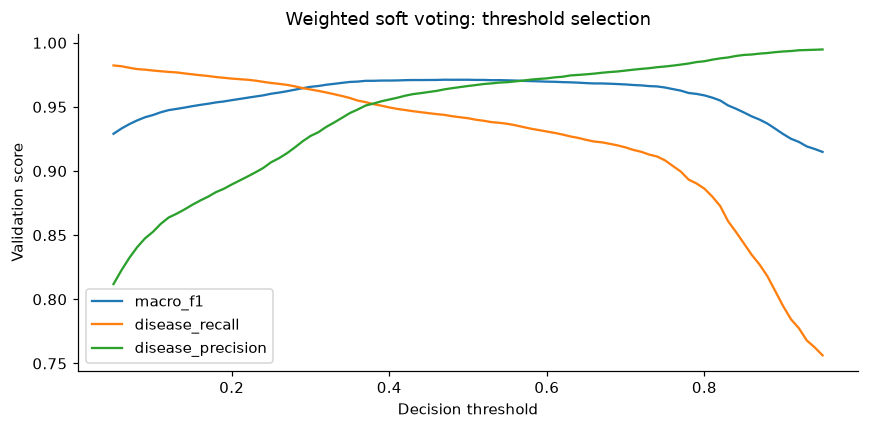

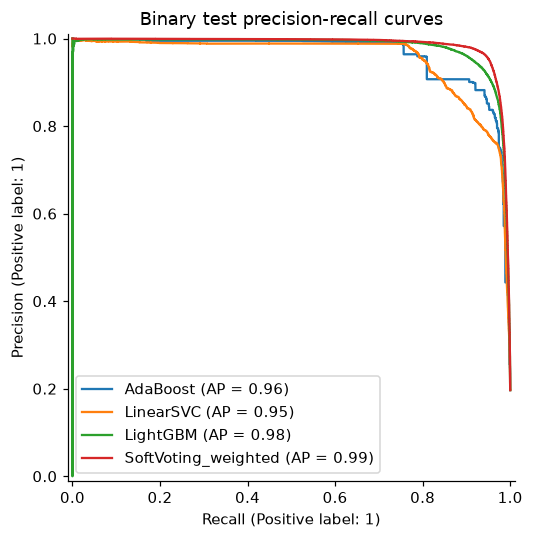

In [10]:
validation_p = models['SoftVoting_weighted']['binary']['validation'][:, 1]
test_p = models['SoftVoting_weighted']['binary']['test'][:, 1]
threshold_rows = []
for threshold in np.linspace(.05, .95, 91):
    decision = (validation_p >= threshold).astype(np.int8)
    probability = np.column_stack([1-decision, decision])
    threshold_rows.append(dict(threshold=float(threshold), **scores(targets['binary'][splits['validation']], probability, 'binary')))
best_threshold = max(threshold_rows, key=lambda row: (row['macro_f1'], row['disease_recall']))['threshold']
feasible = [row for row in threshold_rows if row['disease_precision'] >= .90]
recall_threshold = max(feasible, key=lambda row: (row['disease_recall'], row['macro_f1']))['threshold'] if feasible else None
operating_points = []
for rule, threshold in [('default', .5), ('macro-F1', best_threshold), ('recall-priority', recall_threshold)]:
    if threshold is None:
        continue
    decision = (test_p >= threshold).astype(np.int8)
    operating_points.append(dict(rule=rule, threshold=threshold,
        **scores(targets['binary'][splits['test']], np.column_stack([1-decision, decision]), 'binary')))
operating_points = pd.DataFrame(operating_points)
display(operating_points.round(5))
threshold_curve = pd.DataFrame(threshold_rows)
fig, ax = plt.subplots(figsize=(8, 4))
for metric in ['macro_f1', 'disease_recall', 'disease_precision']:
    ax.plot(threshold_curve['threshold'], threshold_curve[metric], label=metric)
ax.set(xlabel='Decision threshold', ylabel='Validation score', title='Weighted soft voting: threshold selection')
ax.legend()
save_figure(fig, 'binary_thresholds.png')

fig, ax = plt.subplots(figsize=(8, 5))
for name in ['AdaBoost', 'LinearSVC', 'LightGBM', 'SoftVoting_weighted']:
    PrecisionRecallDisplay.from_predictions(targets['binary'][splits['test']], models[name]['binary']['test'][:, 1], name=name, ax=ax)
ax.set(title='Binary test precision-recall curves')
save_figure(fig, 'binary_precision_recall.png')


## Error analysis

The model with the highest validation macro-F1 in each task supplies the error analysis. Four-class confidence-label errors are distinguished from pathogenic-to-benign errors. Subgroups use molecular consequence, variant type and chromosome. Rates are displayed with pathogenic sample counts.

four_class SoftVoting_equal confidence-only errors: 54510
                   precision    recall  f1-score   support

           Benign     0.8297    0.7010    0.7599     62899
    Likely_benign     0.9320    0.9649    0.9481    343480
Likely_pathogenic     0.6329    0.5355    0.5801     44153
       Pathogenic     0.7043    0.7606    0.7313     55507

         accuracy                         0.8722    506039
        macro avg     0.7747    0.7405    0.7549    506039
     weighted avg     0.8682    0.8722    0.8689    506039



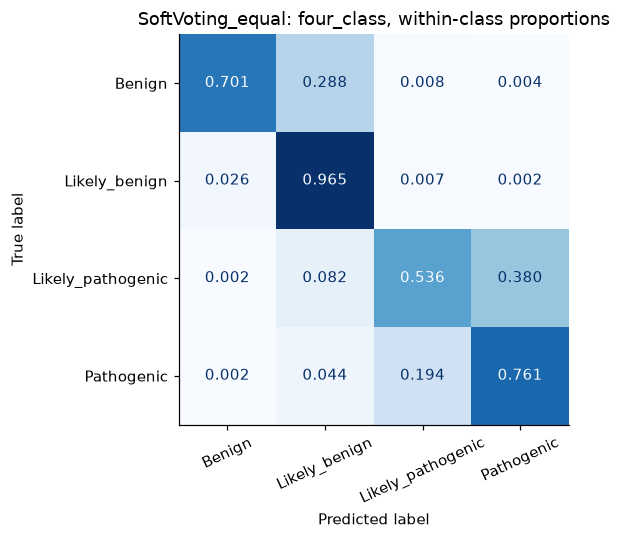

binary SoftVoting_weighted confidence-only errors: 0
                  precision    recall  f1-score   support

    Benign group     0.9855    0.9916    0.9885    406379
Pathogenic group     0.9647    0.9404    0.9524     99660

        accuracy                         0.9815    506039
       macro avg     0.9751    0.9660    0.9704    506039
    weighted avg     0.9814    0.9815    0.9814    506039



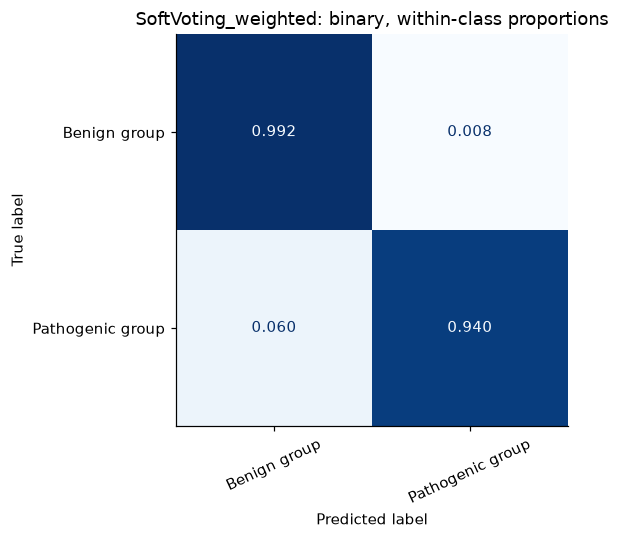

,CHROM,POS,REF,ALT,Primary_Gene,MC_Clean,CLNVC,actual,predicted,disease,false_negative,false_positive,confidence_only_error,task,model
0,3,37090105,G,A,MLH1,intron_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal
1,8,42323443,T,C,SLC20A2,intron_variant,single_nucleotide_variant,3,1,True,True,False,False,four_class,SoftVoting_equal
2,9,137619248,G,A,COL5A1,intron_variant,single_nucleotide_variant,3,1,True,True,False,False,four_class,SoftVoting_equal
3,11,47603692,C,T,NDUFS3,missense_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal
4,1,203832842,G,A,SNRPE,missense_variant,single_nucleotide_variant,3,1,True,True,False,False,four_class,SoftVoting_equal
5,X,47001817,C,T,NDUFB11,missense_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal
6,10,76748839,G,A,KAT6B,synonymous_variant,single_nucleotide_variant,3,1,True,True,False,False,four_class,SoftVoting_equal
7,6,7581474,A,G,DSP,missense_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal
8,6,43488492,T,C,POLR1C,missense_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal
9,17,78024085,A,T,CCDC40,intron_variant,single_nucleotide_variant,2,1,True,True,False,False,four_class,SoftVoting_equal


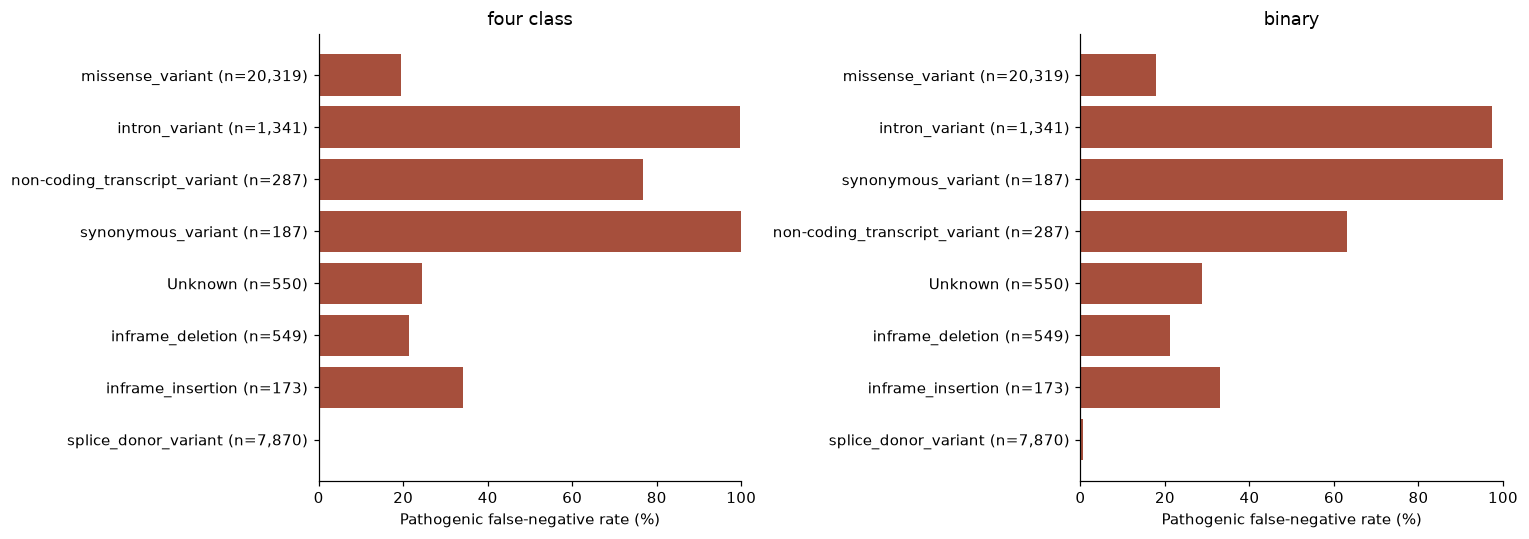

,n,disease_n,false_negatives,false_positives,false_negative_rate,task,model,group,value
63,65308,20319,3656,2442,0.179930,binary,SoftVoting_weighted,MC_Clean,missense_variant
62,154631,1341,1306,29,0.973900,binary,SoftVoting_weighted,MC_Clean,intron_variant
70,156989,187,187,1,1.000000,binary,SoftVoting_weighted,MC_Clean,synonymous_variant
65,31546,287,181,21,0.630662,binary,SoftVoting_weighted,MC_Clean,non-coding_transcript_variant
54,3101,550,158,62,0.287273,binary,SoftVoting_weighted,MC_Clean,Unknown
58,927,549,116,77,0.211293,binary,SoftVoting_weighted,MC_Clean,inframe_deletion
53,7459,94,80,3,0.851064,binary,SoftVoting_weighted,MC_Clean,5_prime_UTR_variant
60,390,173,57,16,0.329480,binary,SoftVoting_weighted,MC_Clean,inframe_insertion
68,8063,7870,42,130,0.005337,binary,SoftVoting_weighted,MC_Clean,splice_donor_variant
52,8054,98,32,13,0.326531,binary,SoftVoting_weighted,MC_Clean,3_prime_UTR_variant


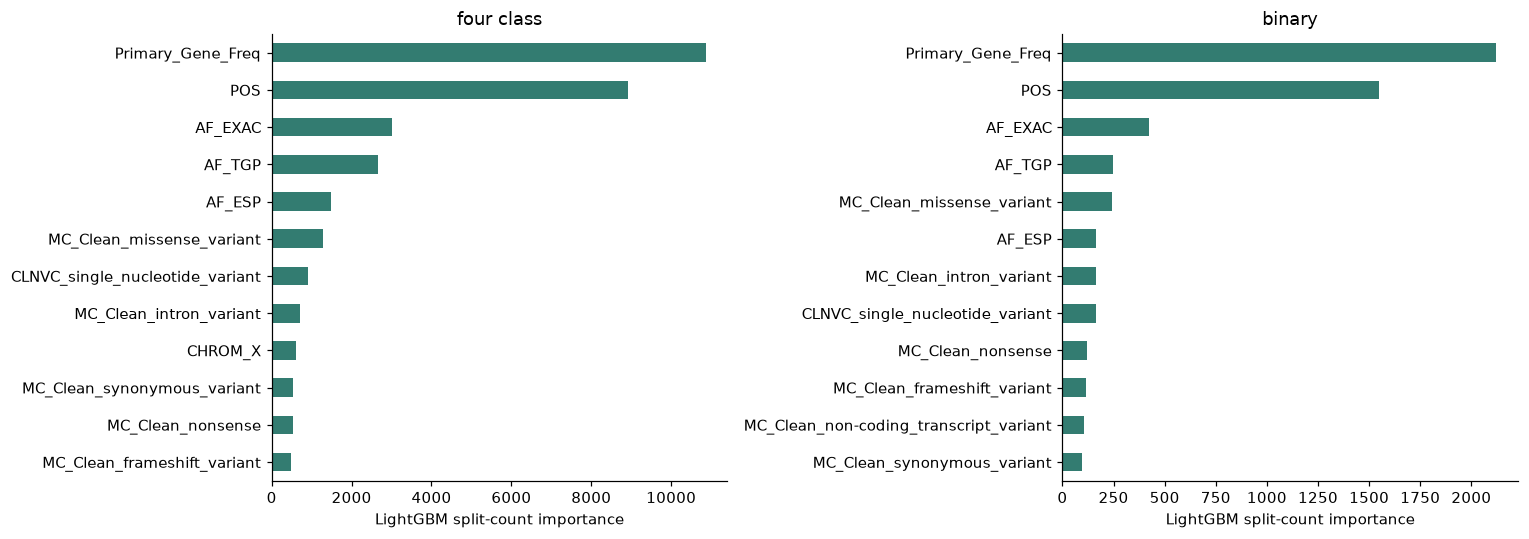

14459

In [11]:
subgroup_frames, error_examples = [], []
for task in ['four_class', 'binary']:
    selected_name = max(models, key=lambda name: models[name][task]['validation_metrics']['macro_f1'])
    selections[task]['error_model'] = selected_name
    probability = models[selected_name][task]['test']
    actual = targets[task][splits['test']]
    predicted = probability.argmax(axis=1)
    disease = actual >= 2 if task == 'four_class' else actual == 1
    disease_pred = predicted >= 2 if task == 'four_class' else predicted == 1
    errors = prepared['data'].iloc[splits['test']][['CHROM', 'POS', 'REF', 'ALT', 'Primary_Gene', 'MC_Clean', 'CLNVC']].copy()
    errors['actual'], errors['predicted'] = actual, predicted
    errors['disease'] = disease
    errors['false_negative'] = disease & ~disease_pred
    errors['false_positive'] = ~disease & disease_pred
    errors['confidence_only_error'] = (actual != predicted) & (disease == disease_pred)
    examples = errors.loc[errors['false_negative']].head(20).copy()
    examples['task'], examples['model'] = task, selected_name
    error_examples.append(examples)
    for column in ['MC_Clean', 'CLNVC', 'CHROM']:
        grouped = errors.groupby(column, observed=True).agg(n=('actual', 'size'), disease_n=('disease', 'sum'),
                   false_negatives=('false_negative', 'sum'), false_positives=('false_positive', 'sum'))
        grouped['false_negative_rate'] = grouped['false_negatives'] / grouped['disease_n'].replace(0, np.nan)
        grouped['task'], grouped['model'], grouped['group'] = task, selected_name, column
        grouped['value'] = grouped.index.astype(str)
        subgroup_frames.append(grouped.reset_index(drop=True))
    print(task, selected_name, 'confidence-only errors:', int(errors['confidence_only_error'].sum()))
    print(classification_report(actual, predicted, target_names=class_names[task], digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay.from_predictions(actual, predicted, display_labels=class_names[task],
        normalize='true', values_format='.3f', cmap='Blues', colorbar=False, xticks_rotation=25, ax=ax)
    ax.set_title(f'{selected_name}: {task}, within-class proportions')
    save_figure(fig, f'confusion_{task}.png')

subgroups = pd.concat(subgroup_frames, ignore_index=True)
error_examples = pd.concat(error_examples, ignore_index=True)
display(error_examples)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task in zip(axes, ['four_class', 'binary']):
    table = subgroups.loc[(subgroups['task'] == task) & (subgroups['group'] == 'MC_Clean') &
                          (subgroups['disease_n'] >= 100)].nlargest(8, 'false_negatives').iloc[::-1]
    labels = [f'{row.value} (n={int(row.disease_n):,})' for row in table.itertuples()]
    ax.barh(labels, table['false_negative_rate'] * 100, color='#a64f3c')
    ax.set(xlabel='Pathogenic false-negative rate (%)', title=task.replace('_', ' '), xlim=(0, 100))
save_figure(fig, 'error_subgroups.png')
display(subgroups.loc[subgroups['group'] == 'MC_Clean'].sort_values(['task', 'false_negatives'], ascending=[True, False]).head(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task in zip(axes, ['four_class', 'binary']):
    importance = pd.Series(models['LightGBM'][task]['base_model'].feature_importances_, index=feature_names)
    importance.nlargest(12).sort_values().plot.barh(ax=ax, color='#337c71')
    ax.set(xlabel='LightGBM split-count importance', title=task.replace('_', ' '))
save_figure(fig, 'feature_importance.png')
del errors
gc.collect()


## Unseen primary genes

A binary LightGBM sensitivity experiment holds out complete primary-gene groups. Unknown-gene records are excluded. Standard sample weighting and the fixed LightGBM hyperparameters are specified independently of the main experiment's variant selection. Grouped fitting, calibration, validation and test genes are disjoint; encoding and gene frequencies are fitted again inside this experiment. A single grouped split has a different cohort and class mix from the random split.

In [12]:
named_rows = np.flatnonzero(prepared['data']['Primary_Gene'].astype(str).to_numpy() != 'Unknown')
groups = prepared['data']['Primary_Gene'].astype(str).to_numpy()
outer = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=73)
development_local, test_local = next(outer.split(named_rows, groups=groups[named_rows]))
development, gene_test = named_rows[development_local], named_rows[test_local]
inner = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=73)
train_local, remaining_local = next(inner.split(development, groups=groups[development]))
gene_train, remaining = development[train_local], development[remaining_local]
last = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=73)
cal_local, val_local = next(last.split(remaining, groups=groups[remaining]))
gene_cal, gene_val = remaining[cal_local], remaining[val_local]
gene_splits = dict(train=gene_train, calibration=gene_cal, validation=gene_val, test=gene_test)
for left, right in itertools.combinations(gene_splits, 2):
    assert not set(groups[gene_splits[left]]) & set(groups[gene_splits[right]])
if gene_experiment is None:
    gene_X, gene_features = encode_features(prepared['data'].iloc[gene_train], prepared['data'])
    def gene_frame(rows):
        return pd.DataFrame(gene_X[rows], columns=gene_features)
    gene_weighting = 'standard'
    gene_weight = None
    gene_base = LGBMClassifier(**LGB_PARAMETERS)
    gene_base.fit(gene_frame(gene_train), targets['binary'][gene_train], sample_weight=gene_weight,
                  eval_X=gene_frame(gene_val), eval_y=targets['binary'][gene_val],
                  callbacks=[early_stopping(25, verbose=False)])
    gene_model = CalibratedClassifierCV(FrozenEstimator(gene_base), method='sigmoid')
    gene_model.fit(gene_frame(gene_cal), targets['binary'][gene_cal])
    gene_probability = predict_checked(gene_model, gene_frame(gene_test), 'binary')
    gene_metrics = scores(targets['binary'][gene_test], gene_probability, 'binary')
    gene_summary = dict(test_rows=len(gene_test), test_genes=len(set(groups[gene_test])),
                        train_rows=len(gene_train), excluded_unknown_rows=len(X)-len(named_rows),
                        disease_fraction=float(targets['binary'][gene_test].mean()), **gene_metrics)
    gene_experiment = dict(model=gene_model, base_model=gene_base, splits=gene_splits,
        feature_names=gene_features, test=gene_probability, test_metrics=gene_metrics, summary=gene_summary)
    checkpoint()
else:
    assert all(np.array_equal(rows, gene_experiment['splits'][name]) for name, rows in gene_splits.items())
    gene_probability = gene_experiment['test']
    gene_metrics = gene_experiment['test_metrics']
    gene_summary = gene_experiment['summary']

display(pd.Series({name: len(rows) for name, rows in gene_splits.items()}, name='Rows'))
display(pd.DataFrame([dict(split='random variants (' + models['LightGBM']['binary']['variant'] + ' weighting)', **models['LightGBM']['binary']['test_metrics']),
                      dict(split='unseen primary genes (standard weighting)', **gene_metrics)]).set_index('split').round(5))
print(classification_report(targets['binary'][gene_test], gene_probability.argmax(axis=1),
                            target_names=class_names['binary'], digits=4, zero_division=0))


train          953746
calibration     90864
validation     117506
test           524339
Name: Rows, dtype: int64

,accuracy,macro_f1,weighted_f1,balanced_accuracy,disease_recall,disease_precision,false_negatives
split,,,,,,,
random variants (balanced weighting),0.97376,0.95875,0.97383,0.96132,0.94079,0.92706,5901
unseen primary genes (standard weighting),0.95121,0.91790,0.94928,0.88917,0.78579,0.96347,22460


                  precision    recall  f1-score   support

    Benign group     0.9488    0.9926    0.9702    419487
Pathogenic group     0.9635    0.7858    0.8656    104852

        accuracy                         0.9512    524339
       macro avg     0.9561    0.8892    0.9179    524339
    weighted avg     0.9517    0.9512    0.9493    524339



## Results

Figures are stored in `figures/`.

In [13]:
for task in ['four_class', 'binary']:
    for name in models:
        item = models[name][task]
        assert np.allclose(item['test'].sum(axis=1), 1, atol=1e-5)
        assert np.isclose(scores(targets[task][splits['test']], item['test'], task)['macro_f1'], item['test_metrics']['macro_f1'])

lines = ['# Additional models: methods and results', '',
    '## Data and preprocessing', '',
    f"The ClinVar dataset contains {len(X):,} variants. Preprocessing follows data7703.ipynb.",
    'The group INFO extraction, first-gene/first-consequence rules, label mappings, zero imputation and eight-feature scheme were reused. Categories and gene frequencies were fitted on training rows.',
    f"The encoded matrix has {len(feature_names)} columns. Fitting, calibration, validation and test sizes are {len(splits['train']):,}, {len(splits['calibration']):,}, {len(splits['validation']):,} and {len(splits['test']):,}. Both tasks use the same test records.",
    'The binary target merges benign/likely benign and pathogenic/likely pathogenic. No VUS records or cancer-specific filtering are represented.', '',
    '## Models and selection', '',
    'AdaBoost used 60 depth-2 trees and learning rate 0.5. LinearSVC used sparse training input, training-fitted scaling without centering, balanced class weights and C in {0.1, 1}. LightGBM used up to 350 trees, 31 leaves and learning rate 0.08 with 25-round validation early stopping.',
    'AdaBoost and LightGBM compared standard and balanced sample weights. All candidates used separate sigmoid probability calibration. Validation macro-F1 selected variants; pathogenic-group recall broke ties. Test data were not used for selection.',
    'Random Forest and XGBoost were retrained using the group model settings on these same partitions, with the same calibration procedure.',
    'Soft voting compared the three additional models (SoftVoting_new) and the validation-best three of all five model families (SoftVoting). Each pool used equal averaging and quarter-step validation-selected weights; at least two weights were positive.', '']
for task in ['four_class', 'binary']:
    lines += [f'## {task.replace("_", " ").title()} results', '',
        '| Model | Accuracy | Macro-F1 | Weighted F1 | Pathogenic recall | Pathogenic precision | False negatives |',
        '|---|---:|---:|---:|---:|---:|---:|']
    for row in comparison.loc[comparison['task'] == task].itertuples():
        lines.append(f'| {row.model} | {row.accuracy:.4f} | {row.macro_f1:.4f} | {row.weighted_f1:.4f} | {row.disease_recall:.4f} | {row.disease_precision:.4f} | {row.false_negatives:,} |')
    variants = {name: models[name][task]['variant'] for name in new_members}
    weights = {prefix: dict(zip(selections[task][prefix]['members'], selections[task][prefix]['weights'])) for prefix in ['SoftVoting_new', 'SoftVoting']}
    lines += ['', f'Selected variants: {variants}.', f'Weighted-vote weights: {weights}.',
              'Four-class pathogenic recall groups the two pathogenic labels; exact-class errors remain in macro-F1.' if task == 'four_class' else '', '']
lines += ['## Binary threshold comparison', '',
          '| Rule | Threshold | Macro-F1 | Recall | Precision | False negatives |', '|---|---:|---:|---:|---:|---:|']
for row in operating_points.itertuples():
    lines.append(f'| {row.rule} | {row.threshold:.2f} | {row.macro_f1:.4f} | {row.disease_recall:.4f} | {row.disease_precision:.4f} | {row.false_negatives:,} |')
lines += ['', 'The recall-priority rule maximized validation recall with validation precision at least 0.90. Its test results describe the observed trade-off; the precision constraint is not guaranteed in future data.', '', '## Error analysis', '']
for task in ['four_class', 'binary']:
    lines += [f"Error-analysis model for {task}: {selections[task]['error_model']} (selected by validation macro-F1)."]
    table = subgroups.loc[(subgroups['task'] == task) & (subgroups['group'] == 'MC_Clean') & (subgroups['disease_n'] >= 100)].nlargest(3, 'false_negatives')
    for row in table.itertuples():
        lines.append(f'- {row.value}: {int(row.false_negatives):,} missed / {int(row.disease_n):,} pathogenic-group records ({100*row.false_negative_rate:.2f}%).')
lines += ['', 'Confidence-only four-class errors were separated from pathogenic-to-benign errors. Subgroup tables and 20 false-negative examples per task are included.', '', '## Unseen primary genes', '',
    f"The additional binary LightGBM test contained {gene_summary['test_rows']:,} variants from {gene_summary['test_genes']:,} primary genes absent from fitting, calibration and validation. Unknown-gene rows excluded: {gene_summary['excluded_unknown_rows']:,}.",
    f"Macro-F1 was {gene_metrics['macro_f1']:.4f}; pathogenic recall was {gene_metrics['disease_recall']:.4f}; precision was {gene_metrics['disease_precision']:.4f}.",
    'Standard weighting and fixed LightGBM hyperparameters were used for this separate experiment. The main random-split binary LightGBM selected balanced weighting. The cohort, class mix and weighting differ, so this is a sensitivity test rather than a direct estimate of the effect of holding out genes. Secondary genes are not isolated.', '',
    '## Files and environment', '',
    'All new training and analysis code is in hao_models.ipynb. Figures are in figures/. data/prepared.joblib stores first-stage data, features and partitions. data/experiment.joblib stores selected additional models, the gene-holdout model and evaluation probabilities. Running all cells reuses saved fits; REFIT_MODELS=True repeats training. DATA specifies the source CSV path.',
    'Python ' + platform.python_version() + '; ' + '; '.join(package + ' ' + version(package) for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'lightgbm', 'matplotlib', 'joblib', 'ipykernel']) + '.',
    'The supplied file was obtained from the shared Google Drive link. Its upstream release date and license remain unverified.']
Path('RESULTS.md').write_text(chr(10).join(lines) + chr(10), encoding='utf-8')
checkpoint()
print('RESULTS.md and', len(list(FIGURES.glob('*.png'))), 'figures saved.')


RESULTS.md and 7 figures saved.
